In [1]:
import numpy
import pandas
import seaborn

from matplotlib import pyplot

from fitting import TIMESERIES_TABLE_PATH
from realistic import PARAMS

In [2]:
pyplot.rcParams["figure.figsize"] = [12.8, 9.6]

In [3]:
def err(obs, model):
    scale = numpy.abs(obs)
    scale[scale == 0] = 1
    return numpy.abs(obs - model) / scale

In [4]:
params = {
    'a': 'fitted_a',
    'b': 'fitted_b',
    'e': 'fitted_e',
    'periapsis_phase': 'fitted_periapsis_phase',
    'Macc': 'fitted_Macc',
    'Porb': 'fitted_porb',
}

In [5]:
results = pandas.read_parquet(TIMESERIES_TABLE_PATH)

In [6]:
results

,a,e,periapsis_phase,Macc,Porb,Mcomp,Rcomp,b,rv,rv_times,...,cadence,baseline,pristine idx,realistic_idx,fitted_a,fitted_b,fitted_Macc,fitted_e,fitted_periapsis_phase,fitted_porb
0,16.428571,0,0,7.083333,8554.662559,1.0,1.0,3.673469,"[9290.949052721178, 15673.419024096298, 21905....","[2460676.5, 2460826.5, 2460976.5, 2461126.5, 2...",...,150,1095,39202,97310,6.134841,6.860516,2.686208,0.687647,4.220511,2890.769092
1,9.357143,0,0,19.583333,2304.387248,1.0,1.0,1.836735,"[110397.22582291038, 167831.63513247413, 19754...","[2460676.5, 2460826.5, 2460976.5, 2461126.5, 2...",...,150,1095,35239,75837,9.313292,7.448011,19.388882,0.010145,2.041075,2299.093221
2,0.164286,0,0,28.958333,4.443644,1.0,1.0,0.408163,"[1848646.405717879, -1180841.6329256678, -1866...","[2460676.5, 2460706.5, 2460736.5, 2460766.5, 2...",...,30,1825,1323,4949,0.232248,7.492395,18.651332,0.709317,3.589800,9.222107
3,0.550000,0,0,18.541667,33.702465,1.0,1.0,3.061224,"[636578.724513172, 783930.2862180413, 641870.5...","[2460676.5, 2460976.5, 2461276.5, 2461576.5, 2...",...,300,1825,9138,86446,1.883568,3.609042,34.716151,0.144188,1.166028,157.993056
4,93.571429,0,0,22.708333,67898.910325,1.0,1.0,3.673469,"[1452.65364446783, 3469.801700248101]","[2460676.5, 2460976.5]",...,300,365,54217,75586,99.646637,6.742690,29.101299,0.292770,3.700679,66221.616232
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,0.935714,0,0,30.000000,59.378944,1.0,1.0,9.591837,"[-580096.7703531287, -793649.7536126388]","[2460676.5, 2460976.5]",...,300,365,17449,58288,1.659116,8.979257,33.329801,0.426663,4.575356,133.222591
4996,0.100000,0,0,17.500000,2.685422,1.0,1.0,1.020408,"[-1618062.541582878, -503620.5020019494, 99028...","[2460676.5, 2460826.5, 2460976.5, 2461126.5, 2...",...,150,1825,137,40264,1.064956,6.205948,23.966865,0.027921,1.298849,80.336730
4997,8.071429,0,0,14.375000,2136.074898,1.0,1.0,10.000000,"[94881.3229915532, 160895.20837079006, 109533....","[2460676.5, 2460976.5, 2461276.5, 2461576.5, 2...",...,300,1825,33734,28789,8.064614,7.880207,14.379229,0.004116,6.277194,2133.076761
4998,1.000000,0,0,16.458333,87.417229,1.0,1.0,2.448980,"[166702.68895771945, 445818.8316521387, -35646...","[2460676.5, 2460826.5, 2460976.5, 2461126.5, 2...",...,150,1825,19061,9739,2.716360,3.127881,6.264372,0.851286,0.532145,606.708738


In [7]:
# for a, b in params:
#     results[f'{a} err'] = numpy.log10(numpy.abs(results[b] - results[a]))

In [8]:
# results['close'] = (
#     numpy.isclose(results['a'], results['fitted_a'], rtol=1)
#     & numpy.isclose(results['Macc'], results['fitted_Macc'], rtol=1)
#     # & numpy.isclose(results['Porb'], results['fitted_porb'], rtol=0.1)
# )
# results['close'].value_counts()

In [9]:
# results[['a', 'b', 'fitted_a', 'Macc', 'fitted_Macc', 'Porb', 'fitted_porb', 'close']]

In [10]:
# # a = seaborn.swarmplot(data=results, x='baseline', y='Porb', hue='close', col='cadence')
# a = seaborn.catplot(
#     data=results, kind="strip",
#     x='baseline', y='Porb', hue='Porb err', col='cadence',
#     aspect=.5, jitter=True,
# )
# pyplot.yscale('log')
# seaborn.move_legend(a, "upper left", bbox_to_anchor=(1, 1))

In [11]:
# # a = seaborn.swarmplot(data=results, x='baseline', y='Porb', hue='close', col='cadence')
# a = seaborn.catplot(
#     data=results, kind="strip",
#     x='baseline', y='Macc', hue='Macc err', col='cadence',
#     aspect=.5, jitter=True,
# )
# seaborn.move_legend(a, "upper left", bbox_to_anchor=(1, 1))

In [12]:
# # a = seaborn.swarmplot(data=results, x='baseline', y='Porb', hue='close', col='cadence')
# a = seaborn.catplot(
#     data=results, kind="strip",
#     x='baseline', y='a', hue='a err', col='cadence',
#     aspect=.5, jitter=True,
# )
# seaborn.move_legend(a, "upper left", bbox_to_anchor=(1, 1))
# pyplot.yscale('log')

In [13]:
# # Scatter plot version
# def plot_relation(x, y='RV accuracy', logx=True, logy=True):
#     for cadence, cadence_group in results.groupby('cadence'):
#         baselines = cadence_group['baseline'].unique()
#         baselines = numpy.sort(baselines)
#         fig, axes = pyplot.subplots(1, len(baselines), figsize=(6 * len(baselines), 5), sharey=True)
#         if len(baselines) == 1:
#             axes = [axes]
#         for ax, baseline in zip(axes, baselines):
#             subset = cadence_group[cadence_group['baseline'] == baseline]
#             ax.set_title(f'Cadence: {cadence}, Baseline: {baseline}')
#             ax.set_xlabel(x)
#             ax.set_ylabel(y)
#             if logx:
#                 ax.set_xscale('log')
#             if logy:
#                 ax.set_yscale('log')
#             colors = subset['close'].map({True: 'tab:blue', False: 'tab:red'})
#             ax.scatter(subset[x], subset[y], c=colors, alpha=0.7, s=4, label=None)
#             handles = [
#                 pyplot.Line2D([0], [0], marker='o', color='w', label='close', markerfacecolor='tab:blue', markersize=8),
#                 pyplot.Line2D([0], [0], marker='o', color='w', label='not close', markerfacecolor='tab:red', markersize=8)
#             ]
#             if ax == axes[0]:
#                 ax.legend(handles=handles, title='close')
#             else:
#                 ax.legend_.remove() if hasattr(ax, 'legend_') and ax.legend_ else None
#         pyplot.tight_layout()
#         pyplot.show()

In [14]:
def plot_relation(x, y='RV accuracy', logx=True, logy=True, bins=20):
    for cadence, cadence_group in results.groupby('cadence'):
        baselines = numpy.sort(cadence_group['baseline'].unique())
        fig, axes = pyplot.subplots(1, len(baselines), figsize=(6 * len(baselines), 5), sharey=True)
        if len(baselines) == 1:
            axes = [axes]
        for ax, baseline in zip(axes, baselines):
            subset = cadence_group[cadence_group['baseline'] == baseline]
            close =  numpy.isclose(subset[x], subset[params[x]], rtol=0.1)
            # Bin the data
            xdata = subset[x]
            ydata = subset[y]
            if logx:
                xbins = numpy.logspace(numpy.log10(xdata.min()), numpy.log10(xdata.max()), bins + 1)
            else:
                xbins = numpy.linspace(xdata.min(), xdata.max(), bins + 1)
            if logy:
                ybins = numpy.logspace(numpy.log10(ydata.min()), numpy.log10(ydata.max()), bins + 1)
            else:
                ybins = numpy.linspace(ydata.min(), ydata.max(), bins + 1)
            # 2D histogram for "close" fraction
            hist_total, _, _ = numpy.histogram2d(xdata, ydata, bins=[xbins, ybins])
            hist_close, _, _ = numpy.histogram2d(xdata[close], ydata[close], bins=[xbins, ybins])
            # Avoid division by zero
            with numpy.errstate(invalid='ignore', divide='ignore'):
                frac_close = hist_close / hist_total
            # Plot
            mesh = ax.pcolormesh(xbins, ybins, frac_close.T, cmap='coolwarm_r', vmin=0, vmax=1)
            ax.set_title(f'Cadence: {cadence}, Baseline: {baseline}')
            ax.set_xlabel(x)
            ax.set_ylabel(y)
            if logx:
                ax.set_xscale('log')
            if logy:
                ax.set_yscale('log')
            fig.colorbar(mesh, ax=ax, label='Fraction close')
        pyplot.tight_layout()
        pyplot.show()

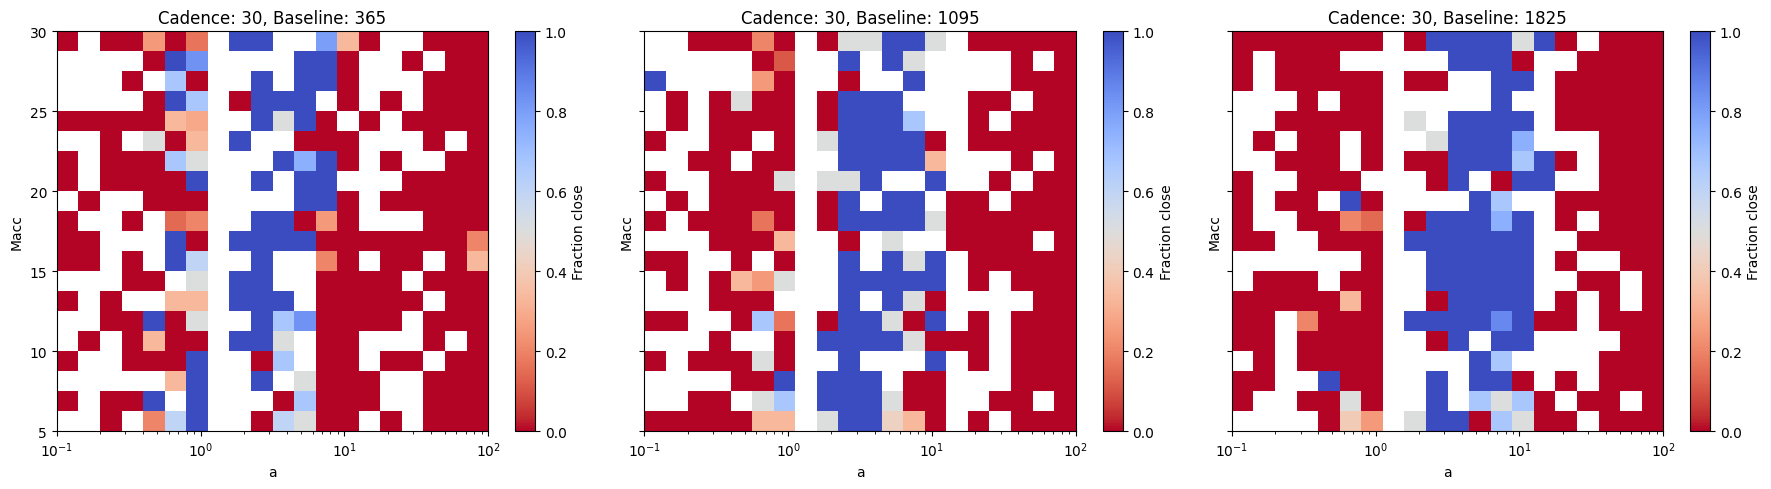

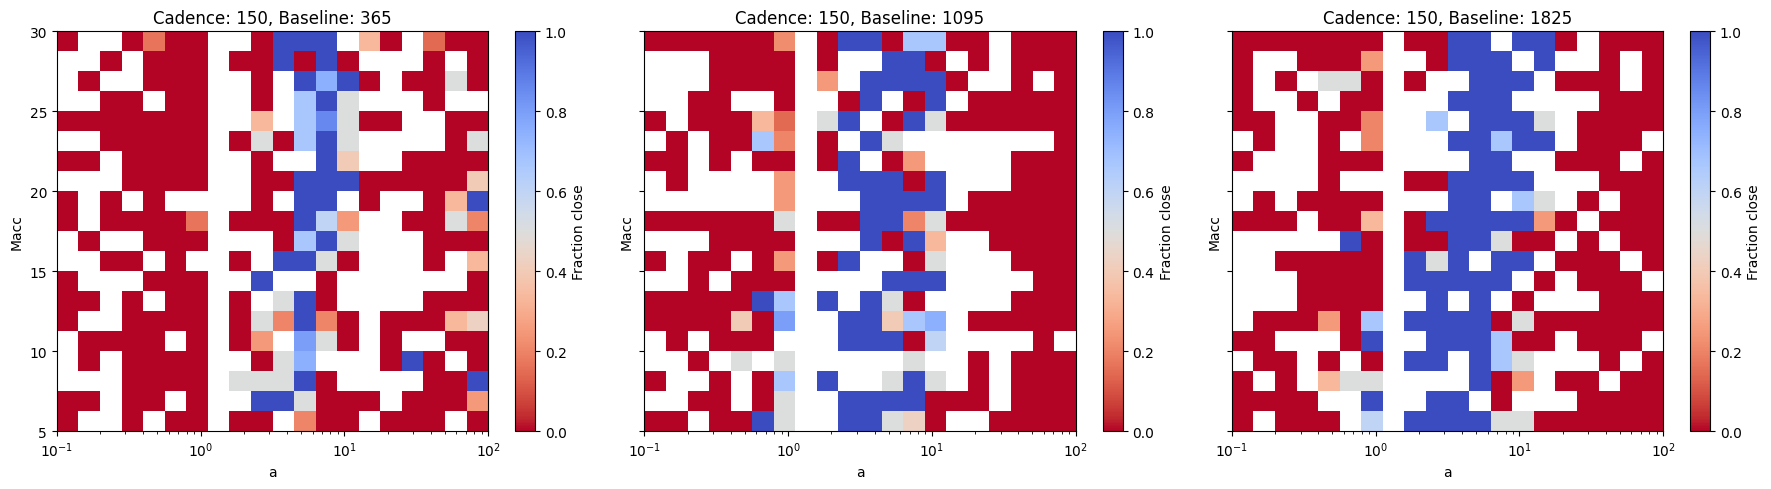

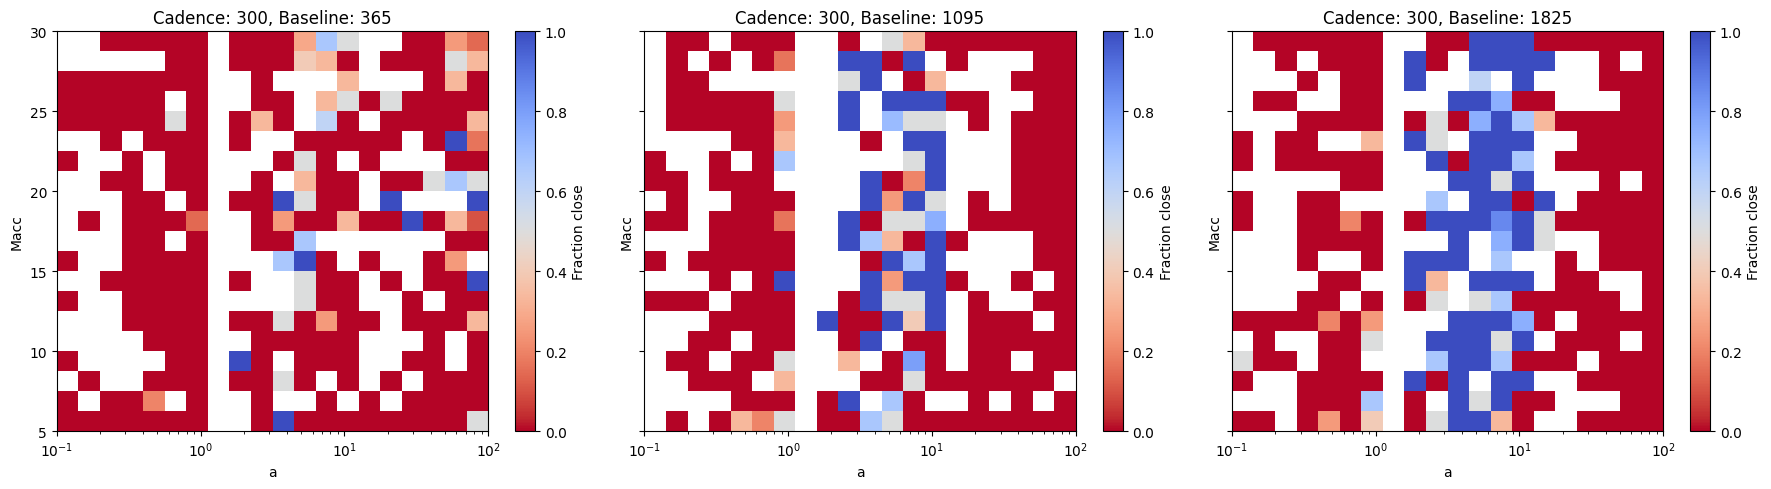

In [15]:
plot_relation('a', 'Macc', logy=False)

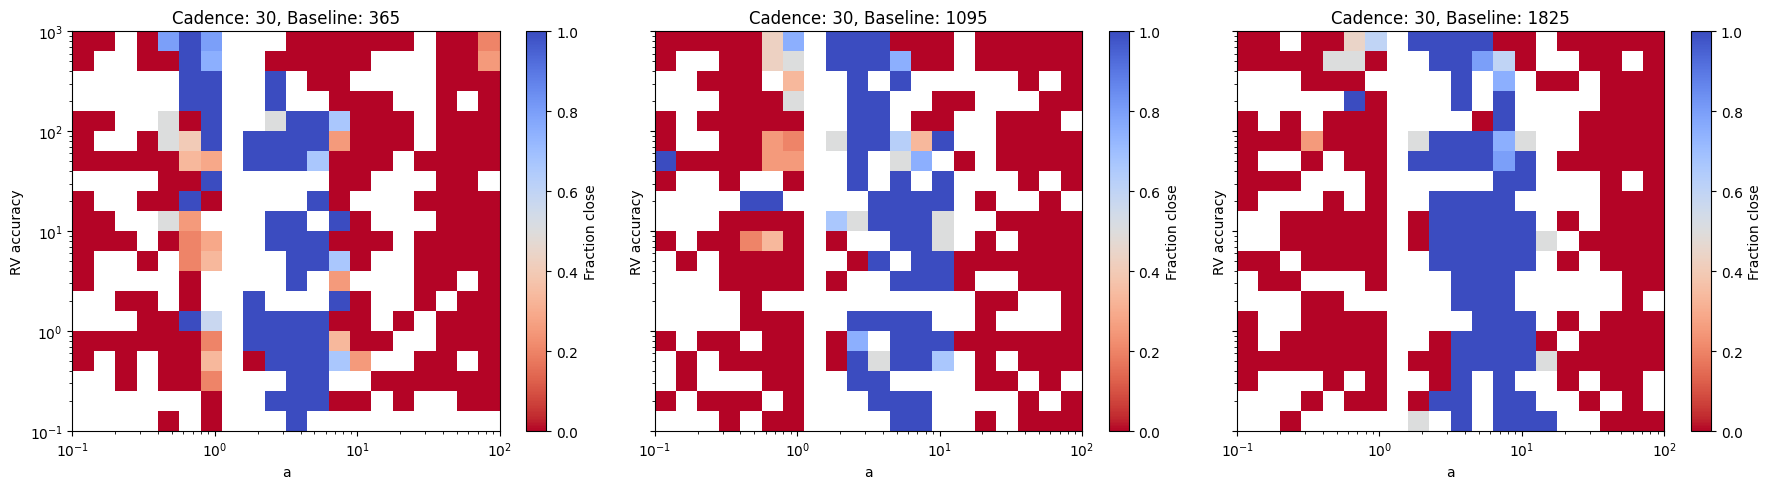

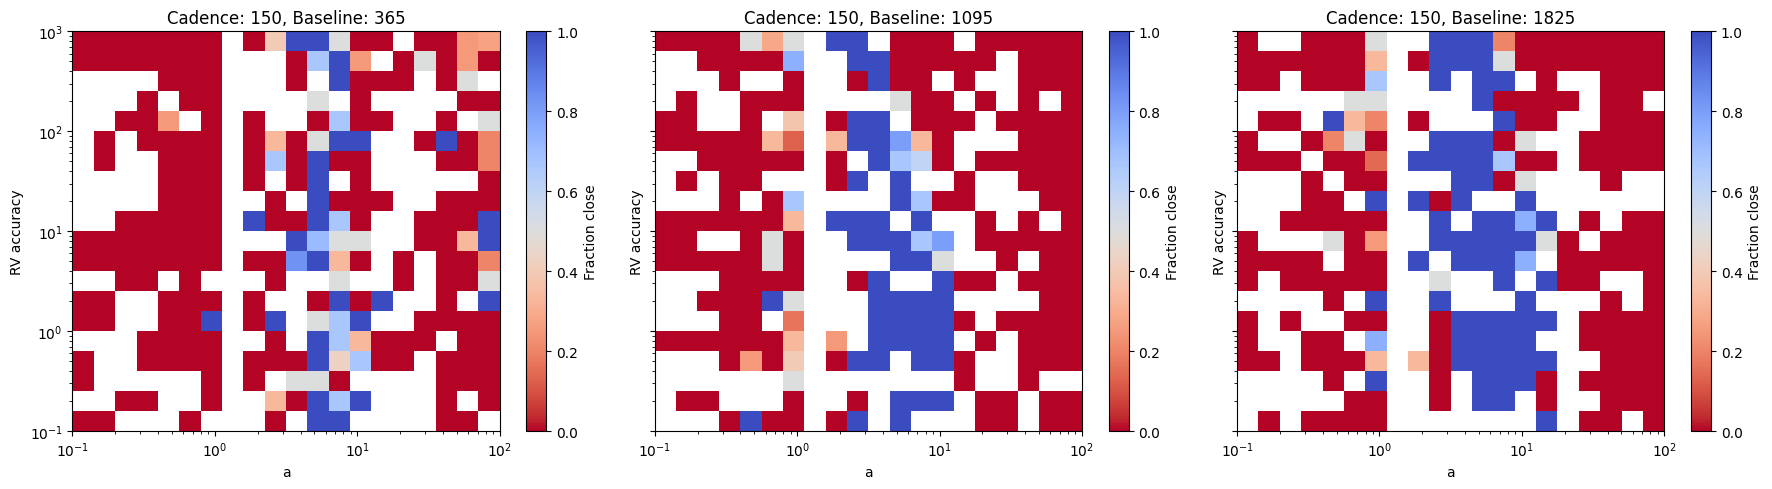

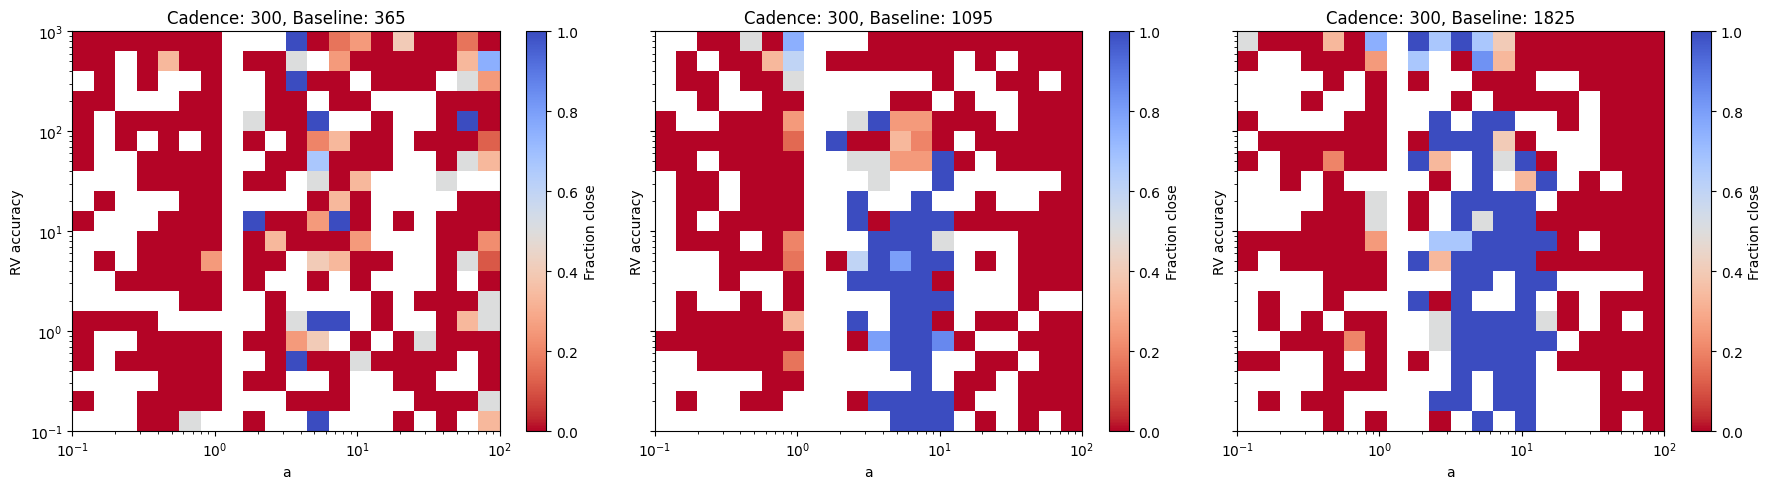

In [16]:
plot_relation('a')

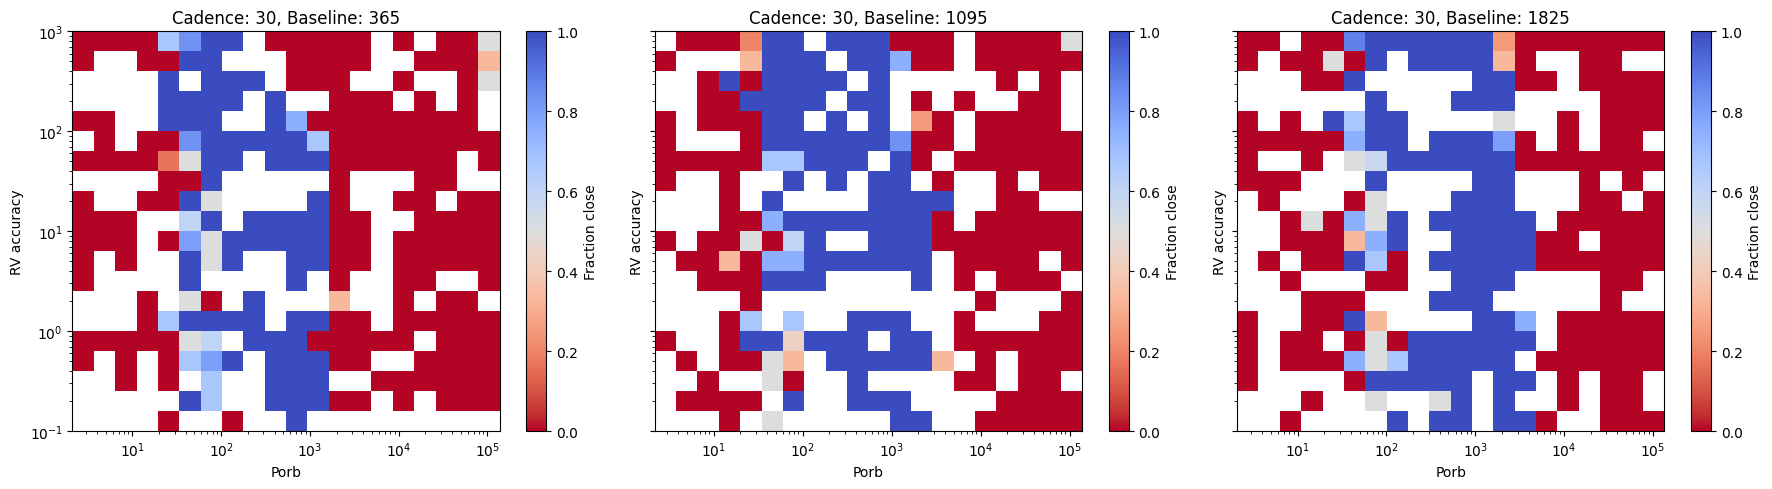

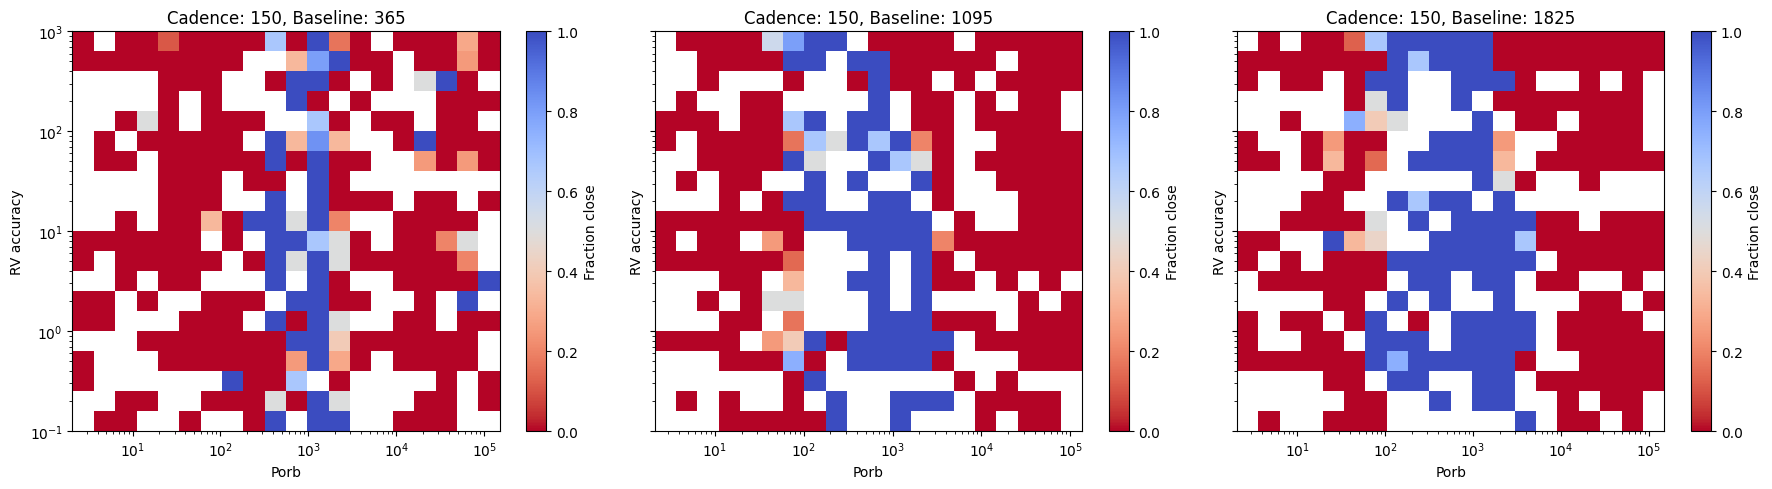

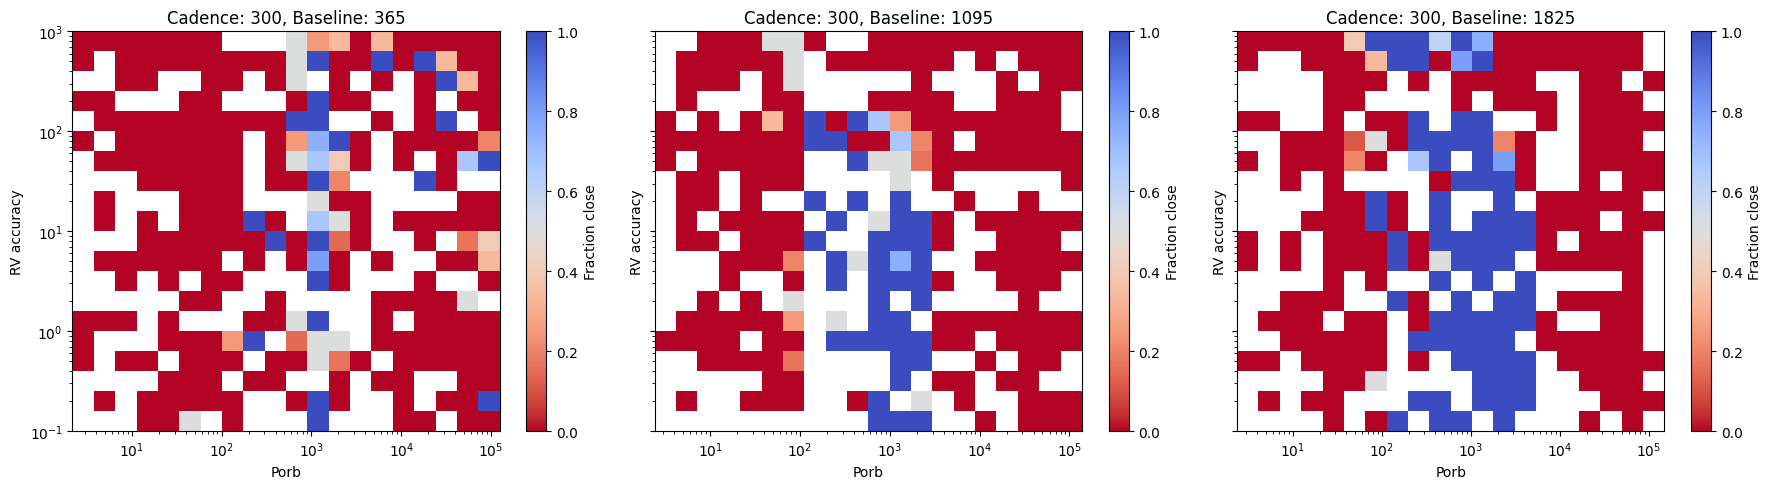

In [17]:
plot_relation('Porb')

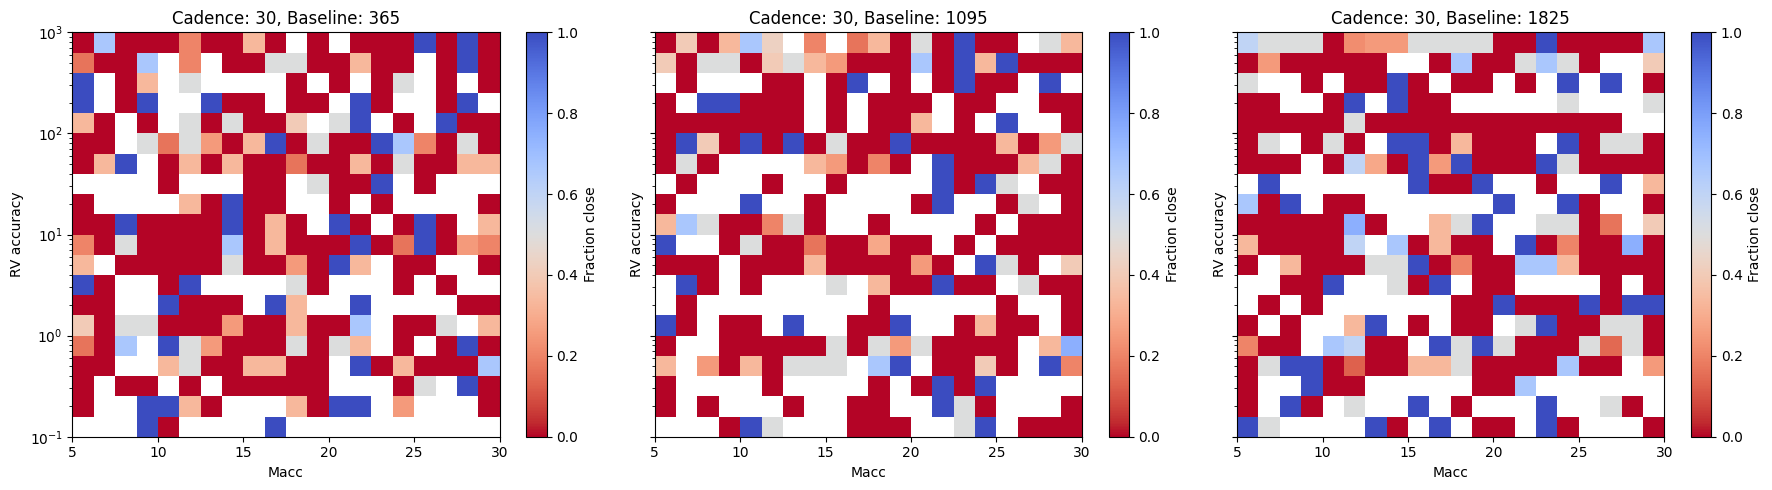

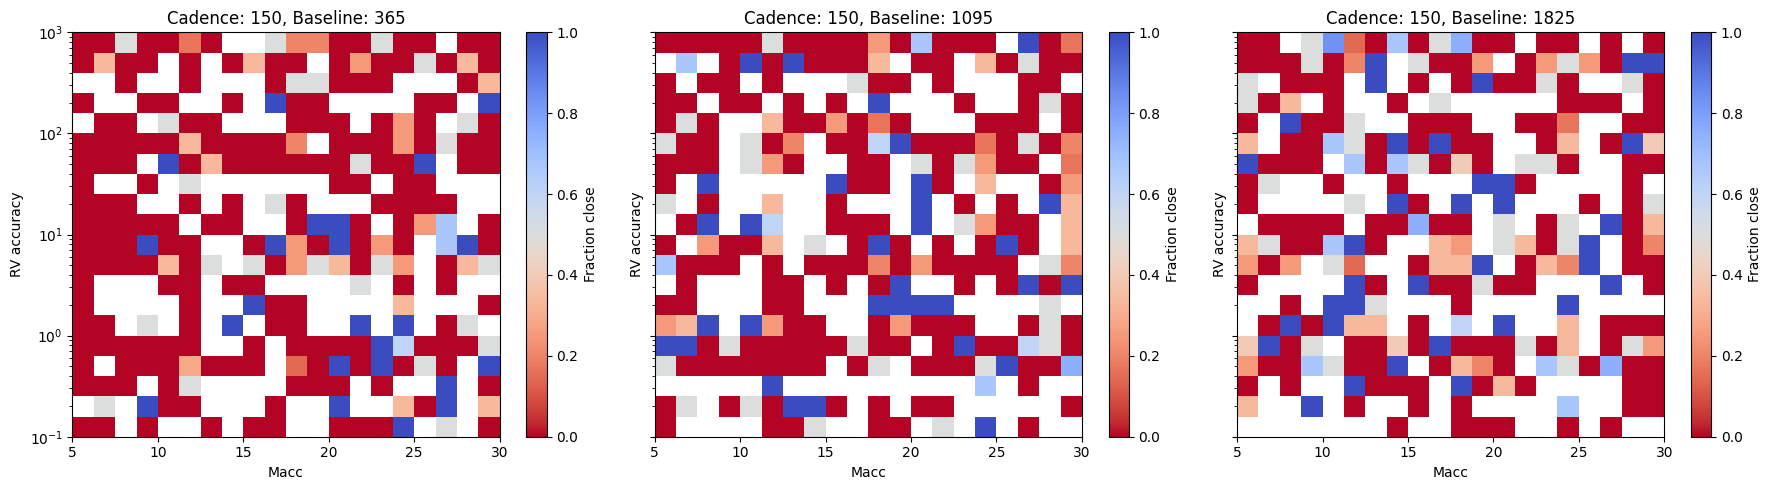

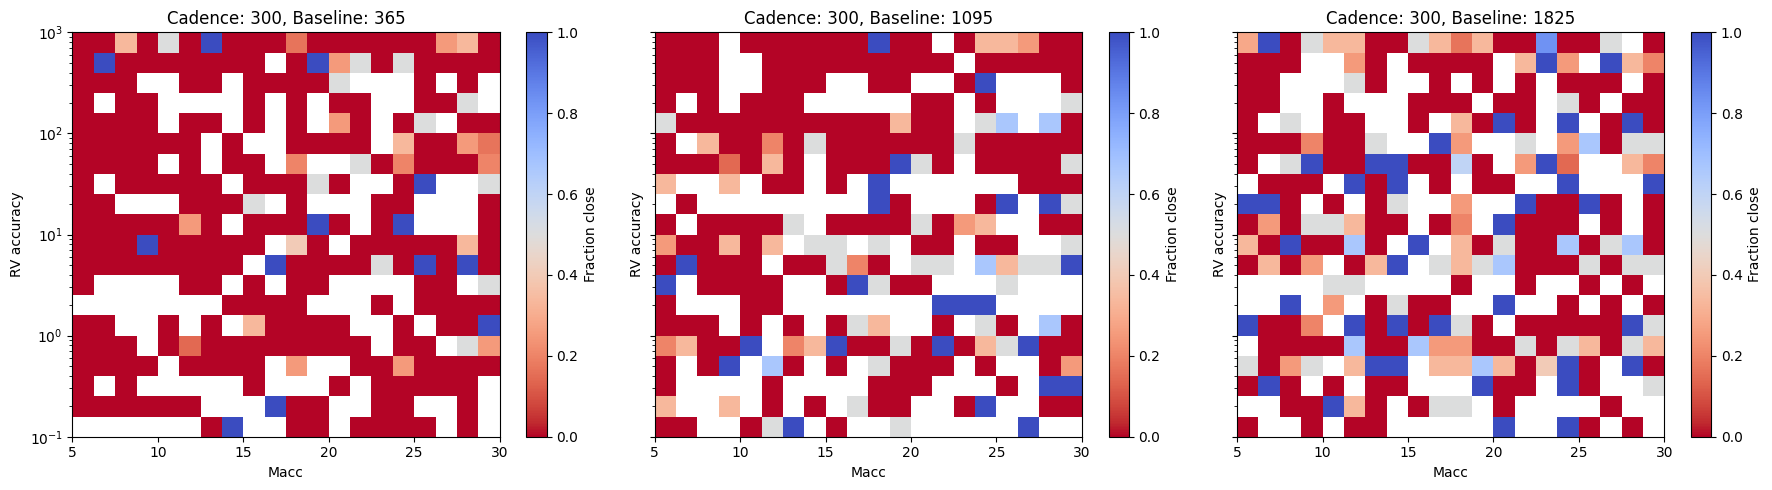

In [18]:
plot_relation('Macc', logx=False)

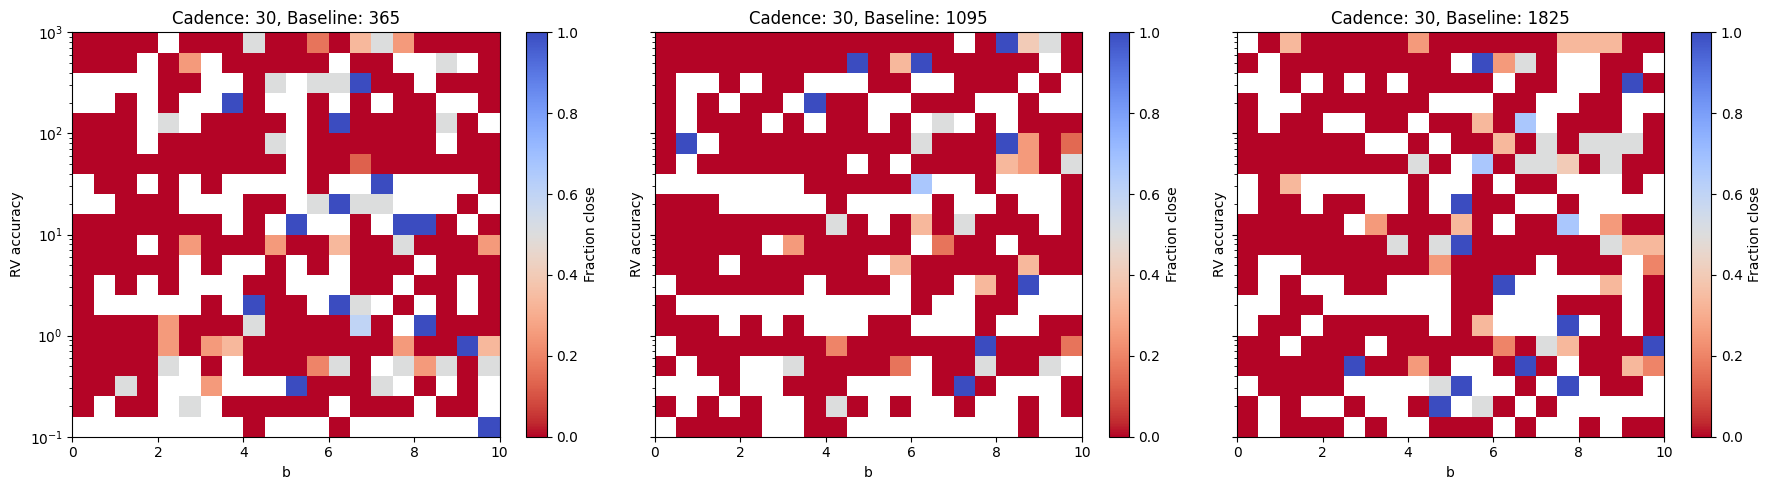

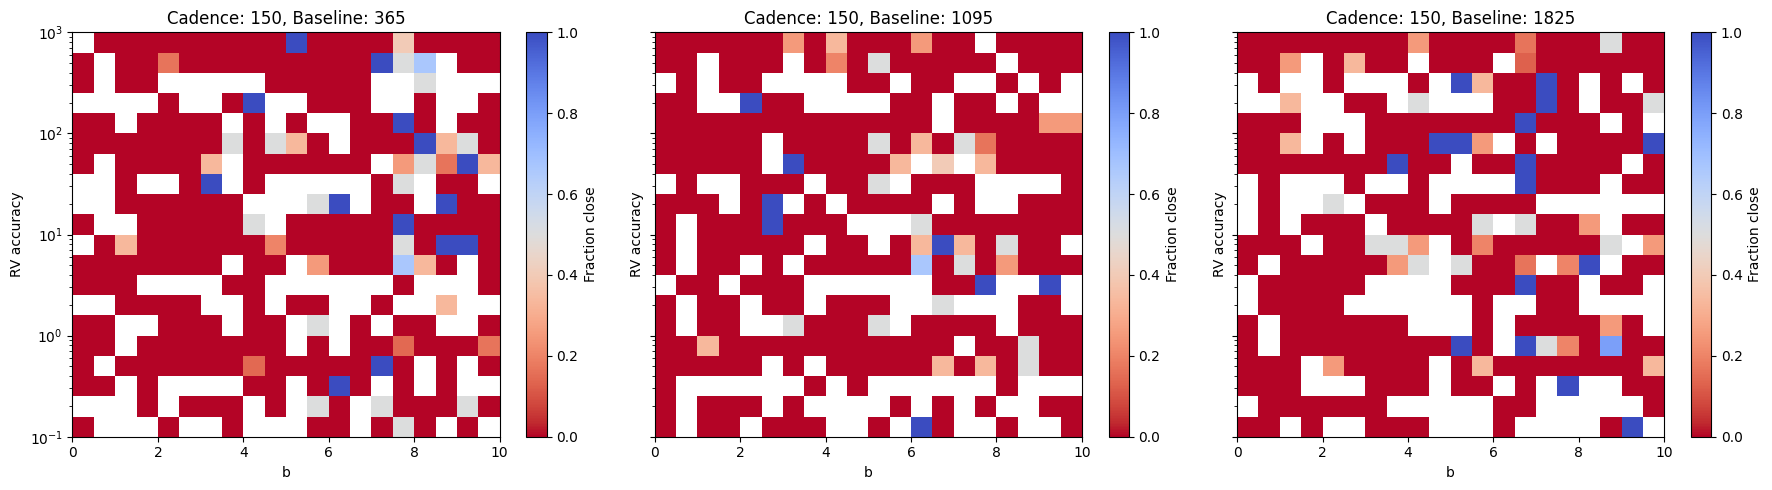

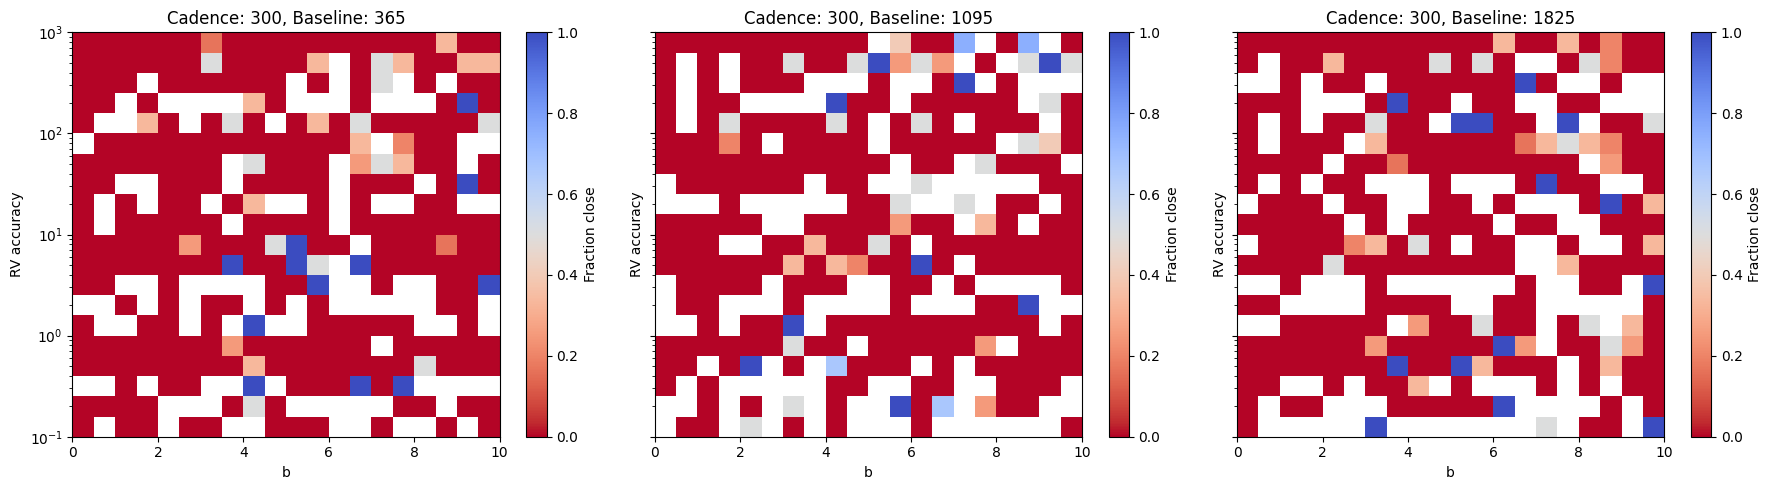

In [19]:
plot_relation('b', logx=False)